In [2]:
import pandas as pd

In [3]:
df = pd.read_csv("BankNote_Authentication.csv")
df.head()

,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


In [4]:
print(df.shape)
df.info()
print(df["class"].value_counts())

(1372, 5)
<class 'pandas.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   variance  1372 non-null   float64
 1   skewness  1372 non-null   float64
 2   curtosis  1372 non-null   float64
 3   entropy   1372 non-null   float64
 4   class     1372 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 53.7 KB
class
0    762
1    610
Name: count, dtype: int64


In [5]:
target = "class"
features = [c for c in df.columns if c != target]
print(features)

['variance', 'skewness', 'curtosis', 'entropy']


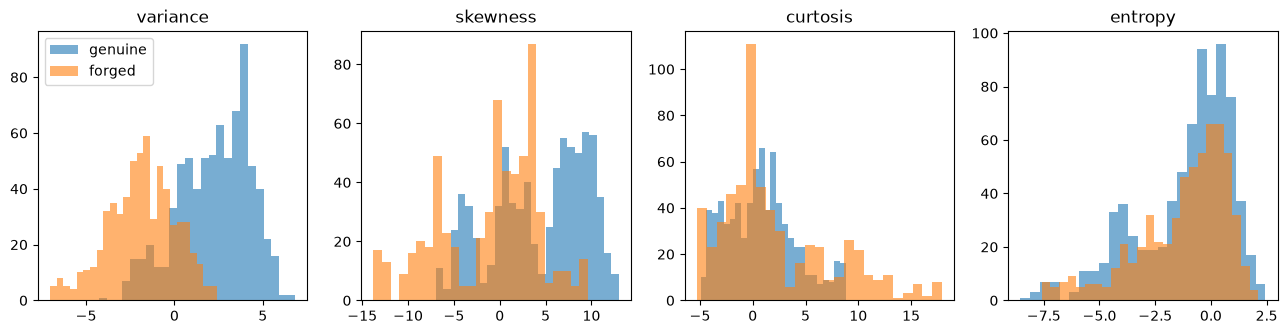

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, col in zip(axes, features):
    for cls, name in [(0, "genuine"), (1, "forged")]:
        ax.hist(df[df[target] == cls][col], bins=25, alpha=0.6, label=name)
    ax.set_title(col)
axes[0].legend()
plt.show()

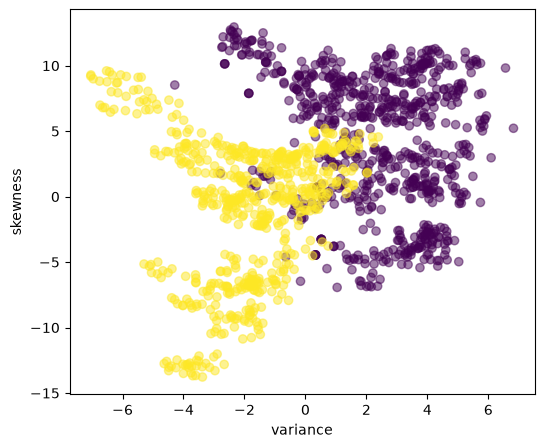

In [7]:
plt.figure(figsize=(6, 5))
plt.scatter(df[features[0]], df[features[1]], c=df[target], alpha=0.5)
plt.xlabel(features[0])
plt.ylabel(features[1])
plt.show()

In [8]:
print(df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())

variance    0
skewness    0
curtosis    0
entropy     0
class       0
dtype: int64
Duplicate rows: 24


In [9]:
from sklearn.model_selection import train_test_split

X = df[features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)

(1097, 4) (275, 4)


In [10]:
from sklearn.dummy import DummyClassifier

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
print("Baseline accuracy:", dummy.score(X_test, y_test))

Baseline accuracy: 0.5563636363636364


In [11]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

clf = make_pipeline(StandardScaler(), LogisticRegression())
clf.fit(X_train, y_train)

print("Train accuracy:", accuracy_score(y_train, clf.predict(X_train)))
print("Test accuracy: ", accuracy_score(y_test, clf.predict(X_test)))

Train accuracy: 0.9845031905195989
Test accuracy:  0.9709090909090909


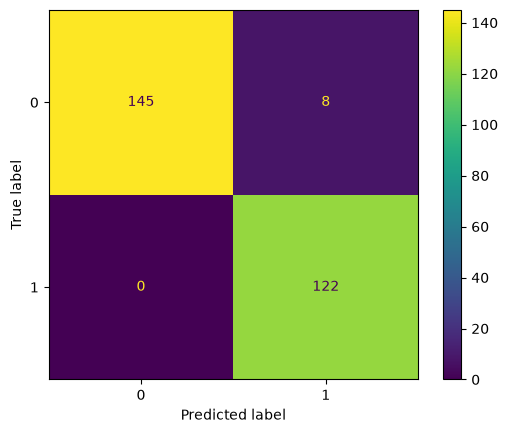

              precision    recall  f1-score   support

           0       1.00      0.95      0.97       153
           1       0.94      1.00      0.97       122

    accuracy                           0.97       275
   macro avg       0.97      0.97      0.97       275
weighted avg       0.97      0.97      0.97       275

Genuine called forged: 8 | Forged called genuine: 0


In [12]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt

pred = clf.predict(X_test)
ConfusionMatrixDisplay.from_predictions(y_test, pred)
plt.show()

print(classification_report(y_test, pred))
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
print("Genuine called forged:", fp, "| Forged called genuine:", fn)

In [13]:
import pandas as pd

weights = clf.named_steps["logisticregression"].coef_[0]
print(pd.Series(weights, index=features).sort_values())

skewness   -4.806524
variance   -4.666009
curtosis   -4.398858
entropy     0.257966
dtype: float64


In [14]:
proba = clf.predict_proba(X_test)[:, 1]
unsure = (proba > 0.2) & (proba < 0.8)
print("Battles the model is unsure about:", unsure.sum())

Battles the model is unsure about: 13


In [15]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(clf, X_train, y_train, cv=5)
print(scores, scores.mean())

[0.98636364 0.98181818 0.97716895 0.99086758 0.98173516] 0.9835907015359071


In [16]:
import joblib, json

joblib.dump(clf, "banknote_model.joblib")
with open("features.json", "w") as f:
    json.dump(features, f)